# 04 · Optimización y sensibilidad de hiperparámetros

**Proyecto:** Predicción de riesgo de burnout organizacional · **Autor:** Oscar Paúl Naranjo Castro
**Maestría en Inteligencia Artificial, UEES** · Todas las rutas son relativas a la raíz del repositorio.

Se aplica la metodología del Workshop de sensibilidad de hiperparámetros: búsqueda bayesiana con Optuna (TPE) con validación cruzada **solo en train**, importancia de hiperparámetros (fANOVA), gráficos *slice*, dependencia parcial sobre un modelo sustituto e interacciones. El test no se toca en este notebook.

In [1]:
%matplotlib inline
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

In [2]:
from IPython.display import Image, display
from src.optimize import main as optimizar, SEARCH_SPACE_DOC
pd.Series(SEARCH_SPACE_DOC, name='rango explorado').to_frame()

,rango explorado
n_estimators,100 a 1000 (entero)
learning_rate,0.01 a 0.30 (log)
max_depth,2 a 10 (entero)
min_child_weight,1 a 20 (log)
subsample,0.5 a 1.0
colsample_bytree,0.5 a 1.0
reg_lambda,0.001 a 10 (log)
reg_alpha,0.001 a 10 (log)


La siguiente celda ejecuta 60 pruebas × 5 pliegues (≈ 2 minutos en CPU) y guarda tablas en `results/metrics` y figuras en `results/figures`.

In [3]:
resumen = optimizar(60)
pd.Series({'XGBoost por defecto': resumen['cv_rmse_default_xgb'],
           'Configuración manual previa': resumen['cv_rmse_manual_config'],
           'Mejor de Optuna': resumen['cv_rmse_best']}, name='RMSE CV').round(5).to_frame()

13:47:14 | INFO | src.data_processing | Datos cargados: 22750 filas, 9 columnas


13:47:14 | INFO | src.data_processing | Filas con objetivo observado: 21626 (se descartaron 1124)


13:47:15 | INFO | src.optimize | RMSE CV XGBoost por defecto: 0.06031 | configuración manual previa: 0.05968


13:48:57 | INFO | src.optimize | Mejor RMSE CV: 0.05930 con {'n_estimators': 642, 'learning_rate': 0.018463575308669898, 'max_depth': 5, 'min_child_weight': 3.5915069689506107, 'subsample': 0.531628116389147, 'colsample_bytree': 0.9751145856654564, 'reg_lambda': 0.1940942172169157, 'reg_alpha': 0.0059027254266686684}


,RMSE CV
XGBoost por defecto,0.06031
Configuración manual previa,0.05968
Mejor de Optuna,0.05930


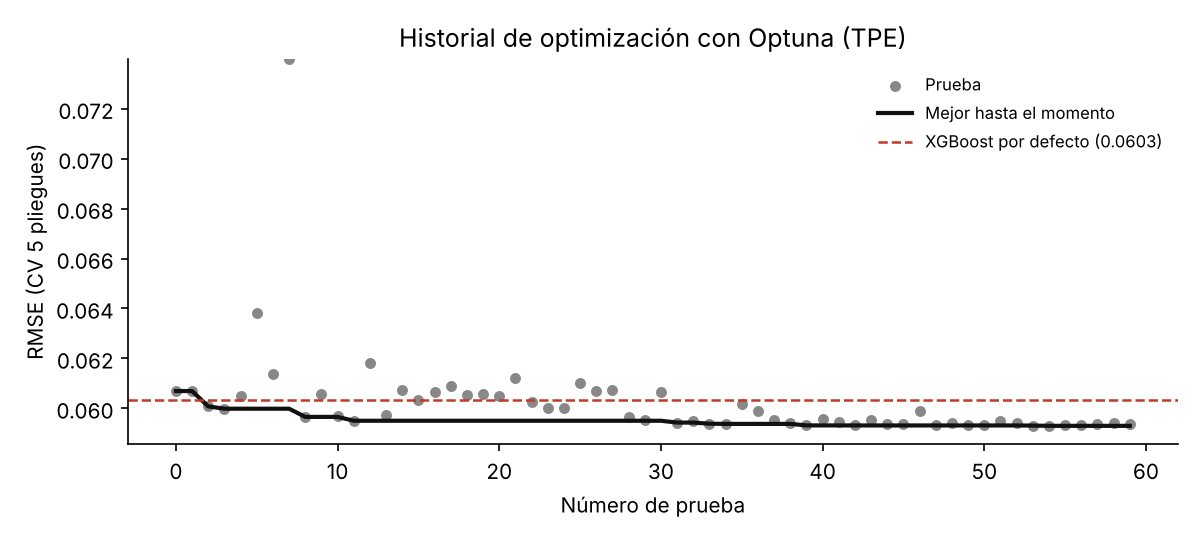

In [4]:
display(Image(FIG / 'opt_history.png'))

## Importancia de hiperparámetros

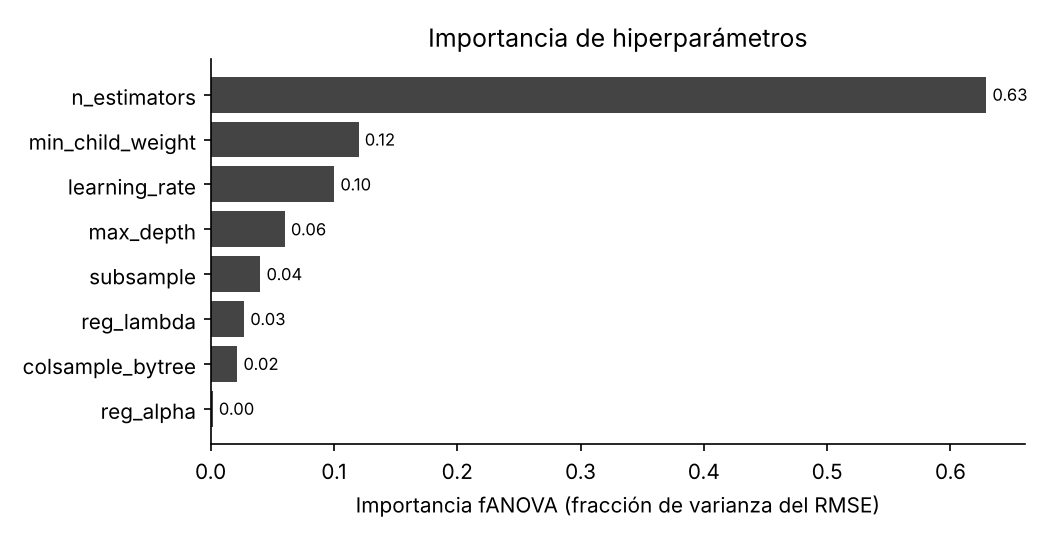

n_estimators        0.629
min_child_weight    0.120
learning_rate       0.100
max_depth           0.060
subsample           0.040
reg_lambda          0.027
colsample_bytree    0.022
reg_alpha           0.002
dtype: float64

In [5]:
display(Image(FIG / 'opt_param_importance.png'))
pd.Series(resumen['param_importance']).round(3)

## Efecto individual: slice y dependencia parcial

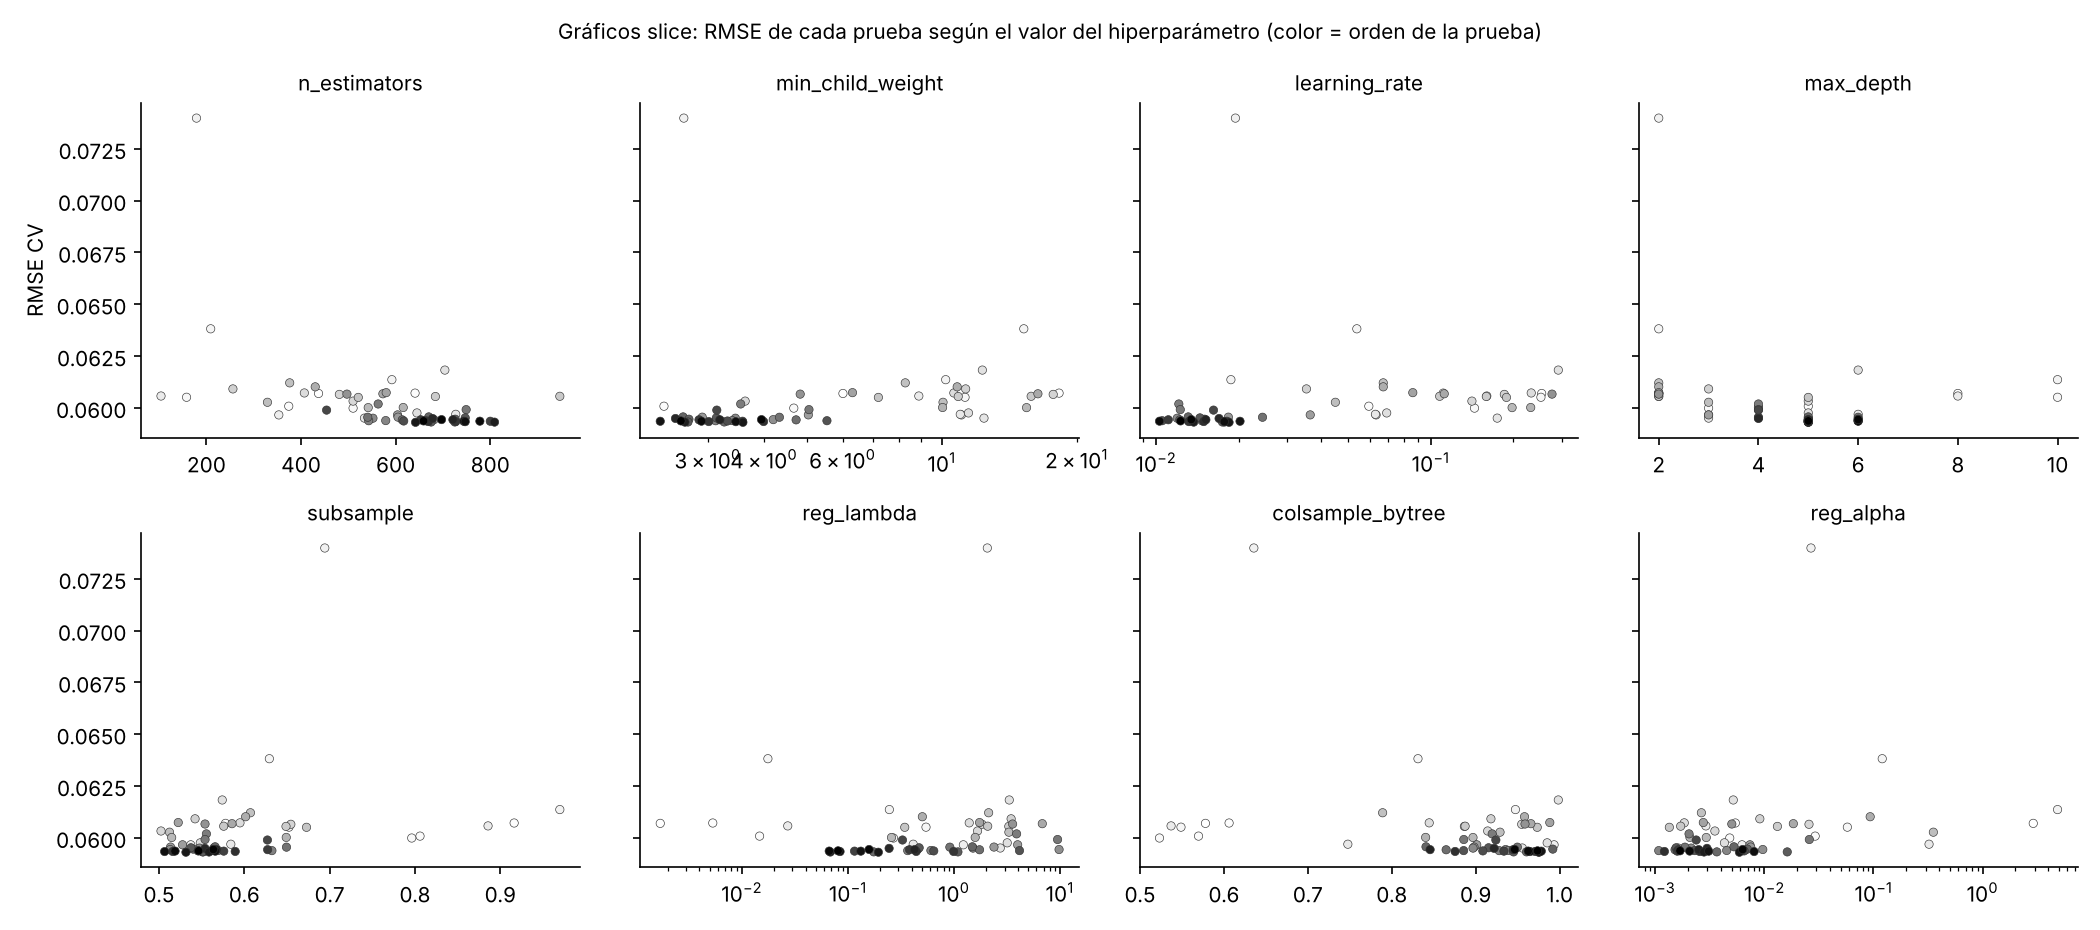

In [6]:
display(Image(FIG / 'opt_slices.png'))

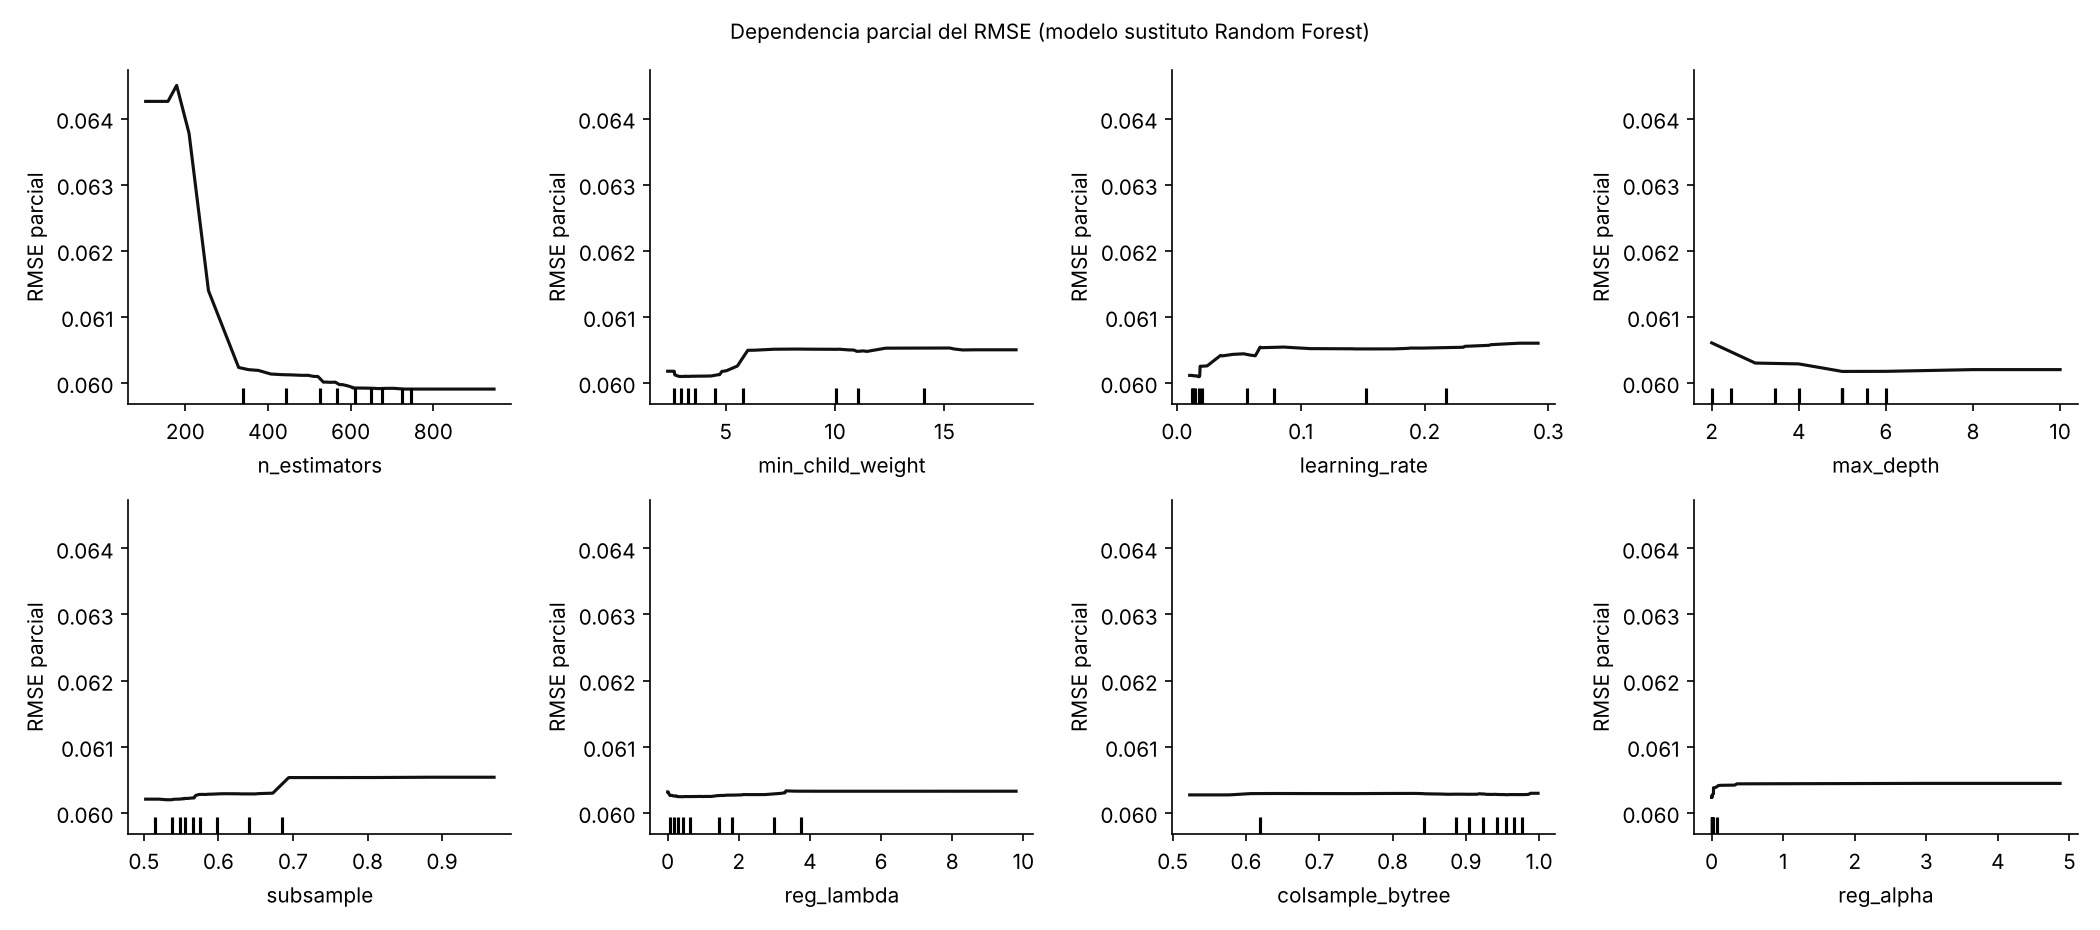

In [7]:
display(Image(FIG / 'opt_pdp.png'))

## Interacciones

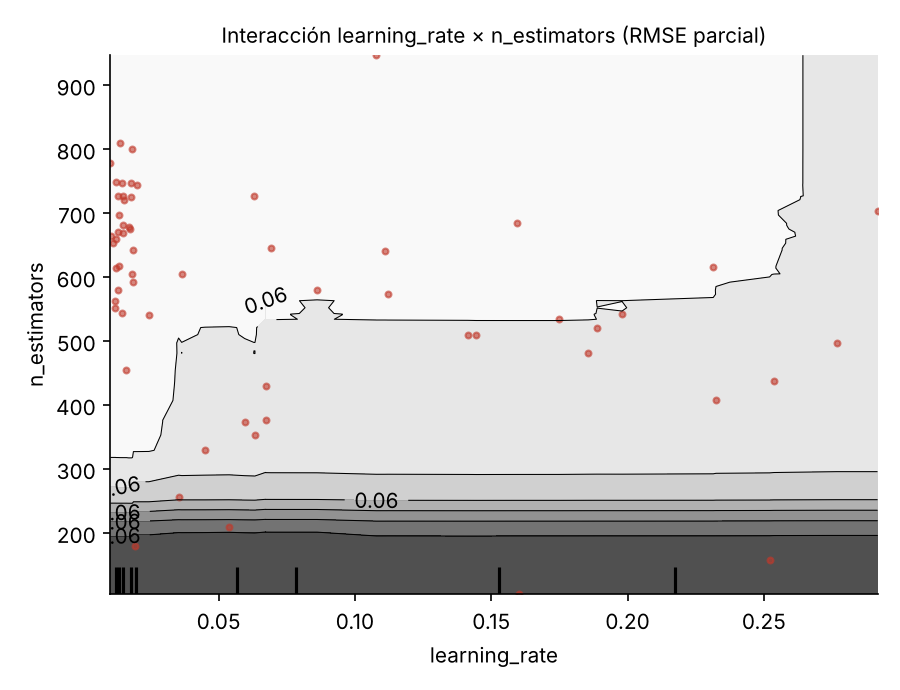

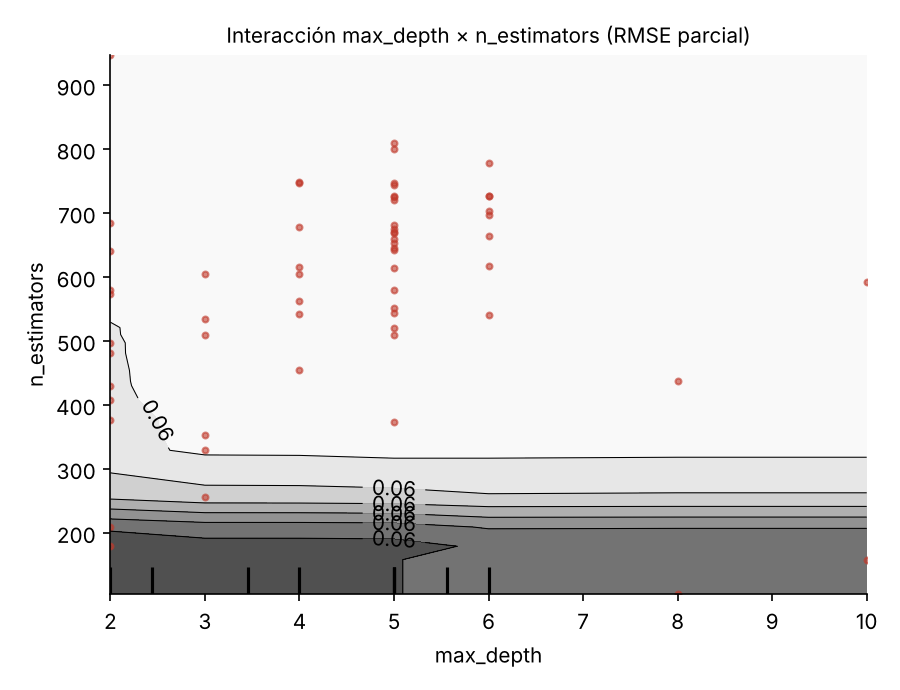

n_estimators x min_child_weight    0.035
max_depth x n_estimators           0.043
learning_rate x n_estimators       0.038
Name: H de Friedman (0 = sin interacción), dtype: float64

In [8]:
display(Image(FIG / 'opt_interaction_lr_trees.png'))
display(Image(FIG / 'opt_interaction_depth_trees.png'))
pd.Series(resumen['interaction_H'], name='H de Friedman (0 = sin interacción)').round(3)

In [9]:
trials = pd.read_csv(ROOT / 'results/metrics/optuna_trials.csv')
q = trials['value'].quantile([0, .1, .5, .9])
print(f"Rango del RMSE entre pruebas: mejor {q[0]:.4f}, percentil 10 {q[.1]:.4f}, mediana {q[.5]:.4f}, percentil 90 {q[.9]:.4f}")
print('Mejores hiperparámetros:'); pd.Series(resumen['best_params']).round(4)

Rango del RMSE entre pruebas: mejor 0.0593, percentil 10 0.0593, mediana 0.0597, percentil 90 0.0609
Mejores hiperparámetros:


n_estimators        642.0000
learning_rate         0.0185
max_depth             5.0000
min_child_weight      3.5915
subsample             0.5316
colsample_bytree      0.9751
reg_lambda            0.1941
reg_alpha             0.0059
dtype: float64

## Conclusiones
1. **n_estimators** concentra la mayor importancia: con menos de unos 300 árboles el modelo queda subajustado; por encima, el RMSE se estabiliza.
2. **learning_rate** y **min_child_weight** tienen efecto secundario; tasas de aprendizaje bajas (≈ 0.02) con muchos árboles dan los mejores resultados.
3. **reg_alpha**, **colsample_bytree** y **reg_lambda** casi no influyen: pueden fijarse sin perder desempeño.
4. Las interacciones medidas son débiles en el rango explorado; el contorno *learning_rate × n_estimators* muestra la compensación clásica (menos tasa requiere más árboles).
5. La mejora frente a XGBoost por defecto es real pero modesta (≈ 1.7 % de RMSE): el modelo está cerca del límite que permiten las variables disponibles. La configuración final se fija en `config.yaml`.